# 7. Componente temporal (2.6)

El análisis usa el **periodo de entrenamiento**: sismos hasta noviembre de 2020 y meses objetivo hasta
esa fecha. La única excepción es la sección 7.7, que compara entrenamiento y prueba para medir la
deriva. Es descriptiva y no alimenta ninguna decisión.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Catálogo y panel de entrenamiento para el análisis temporal
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings("ignore")
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
fin_tr = datos.fecha_de_mes(info["m_test"] - cfg.GAP_MESES)[0]
cat = ev_[ev_.time < fin_tr].copy()

## 7.1 Validación de la variable temporal

In [3]:
# Validación de la serie: días sin sismos, rachas y meses del panel
dias = pd.date_range(cat.time.min().normalize(), fin_tr - pd.Timedelta(days=1), freq="D")
por_dia = cat.groupby(cat.time.dt.normalize()).size().reindex(dias, fill_value=0)
rachas = (por_dia == 0).astype(int)
mas_larga = int(rachas.groupby((rachas != rachas.shift()).cumsum()).sum().max())
meses_panel = np.unique(info["tm"][tr])
val = pd.DataFrame([
    ("Formato", "datetime64 (fecha-hora con segundos)"),
    ("Zona horaria", "UTC según ambos portales (hora local = UTC − 5)"),
    ("Cobertura", f"{cat.time.min():%Y-%m-%d} a {cat.time.max():%Y-%m-%d}"),
    ("Frecuencia del catálogo", "irregular (proceso puntual)"),
    ("Frecuencia del panel", "mensual regular"),
    ("Marcas de tiempo repetidas (mismo segundo)", int(cat.time.duplicated().sum())),
    ("Días sin ningún sismo", f"{int((por_dia == 0).sum())} de {len(por_dia)} ({es((por_dia == 0).mean(), 1, pct=True)})"),
    ("Racha más larga sin sismos (días)", mas_larga),
    ("Meses sin sismos en el catálogo", int((cat.groupby(cat.time.dt.to_period('M')).size().reindex(pd.period_range(cat.time.min(), fin_tr - pd.Timedelta(days=1), freq='M'), fill_value=0) == 0).sum())),
    ("Meses objetivo del panel de entrenamiento (consecutivos)", f"{len(meses_panel)} (huecos: {int((np.diff(meses_panel) != 1).sum())})"),
], columns=["chequeo", "resultado"])
eda.guardar_tabla(val, "validacion_temporal.csv")
val

,chequeo,resultado
0,Formato,datetime64 (fecha-hora con segundos)
1,Zona horaria,UTC según ambos portales (hora local = UTC − 5)
2,Cobertura,2004-01-01 a 2020-11-30
3,Frecuencia del catálogo,irregular (proceso puntual)
4,Frecuencia del panel,mensual regular
5,Marcas de tiempo repetidas (mismo segundo),28
6,Días sin ningún sismo,"168 de 6179 (2,7 %)"
7,Racha más larga sin sismos (días),16
8,Meses sin sismos en el catálogo,0
9,Meses objetivo del panel de entrenamiento (con...,190 (huecos: 0)


In [4]:
md(f"""**Interpretación.**
- **Formato, zona horaria y continuidad.** La variable temporal es consistente: fecha-hora en UTC, sin huecos de cobertura. El panel
  mensual es regular ({len(meses_panel)} meses consecutivos).
- **Marcas repetidas.** Hay {int(cat.time.duplicated().sum())} sismos con el mismo segundo que otro. Son sismos distintos en lugares distintos
  (los duplicados exactos se eliminaron en el capítulo 2).
- **Días sin sismos.** Son {es((por_dia == 0).mean(), 1, pct=True)} y la racha más larga es de {mas_larga} días: el catálogo no tiene interrupciones
  largas que sugieran caídas de la red.""")

**Interpretación.**
- **Formato, zona horaria y continuidad.** La variable temporal es consistente: fecha-hora en UTC, sin huecos de cobertura. El panel
  mensual es regular (190 meses consecutivos).
- **Marcas repetidas.** Hay 28 sismos con el mismo segundo que otro. Son sismos distintos en lugares distintos
  (los duplicados exactos se eliminaron en el capítulo 2).
- **Días sin sismos.** Son 2,7 % y la racha más larga es de 16 días: el catálogo no tiene interrupciones
  largas que sugieran caídas de la red.

## 7.2 Serie completa y agregaciones (hora, día, semana, mes)

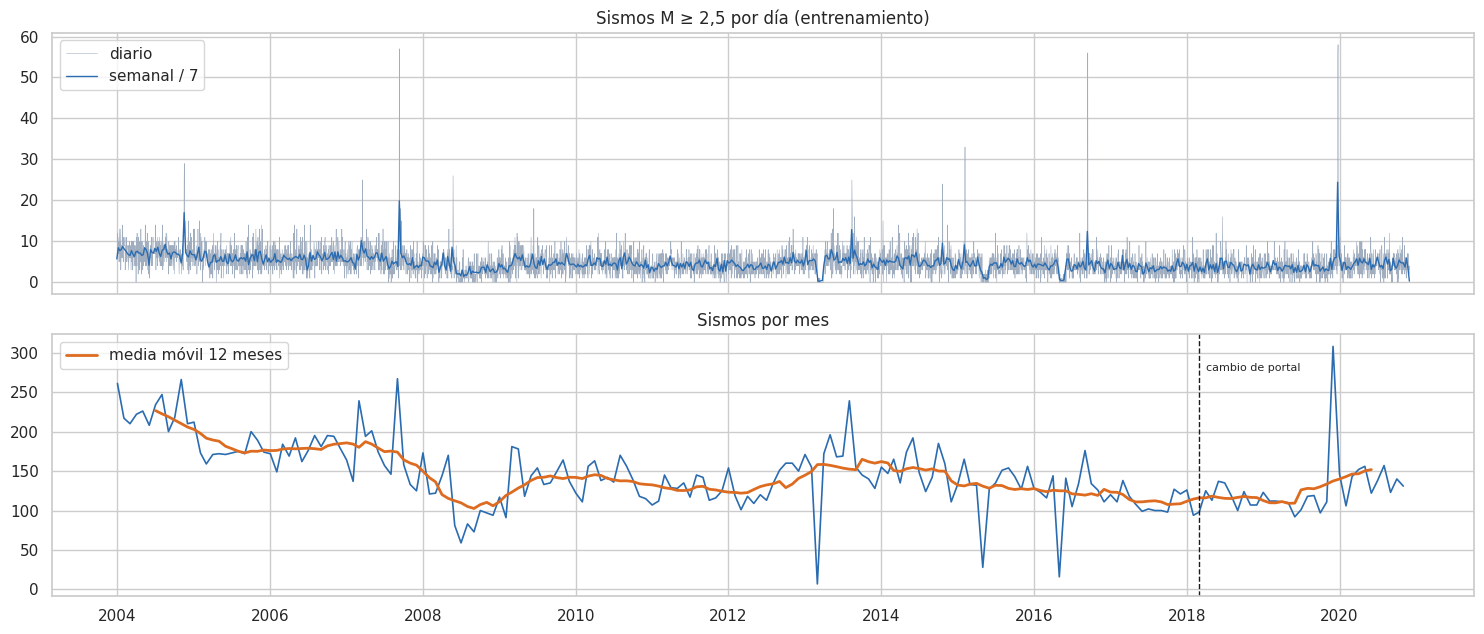

In [5]:
# Series diaria, semanal y mensual de sismos
mensual = cat.groupby(cat.time.dt.to_period("M")).size()
mensual.index = mensual.index.to_timestamp()
semanal = cat.groupby(cat.time.dt.to_period("W")).size()
semanal.index = semanal.index.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
axes[0].plot(por_dia.index, por_dia.values, lw=0.4, color="#a0aec0", label="diario")
axes[0].plot(semanal.index, semanal.values / 7, lw=1, color="#2b6cb0", label="semanal / 7")
axes[0].legend(); axes[0].set_title("Sismos M ≥ 2,5 por día (entrenamiento)")
axes[1].plot(mensual.index, mensual.values, lw=1.2, color="#2b6cb0")
axes[1].plot(mensual.index, mensual.rolling(12, center=True).mean(), lw=2, color="#dd6b20", label="media móvil 12 meses")
axes[1].axvline(pd.Timestamp("2018-03-01"), ls="--", c="k", lw=1); axes[1].text(pd.Timestamp("2018-04-01"), mensual.max() * 0.9, "cambio de portal", fontsize=8)
axes[1].legend(); axes[1].set_title("Sismos por mes")
plt.tight_layout(); eda.guardar_figura(fig, "07_serie.png"); plt.show()

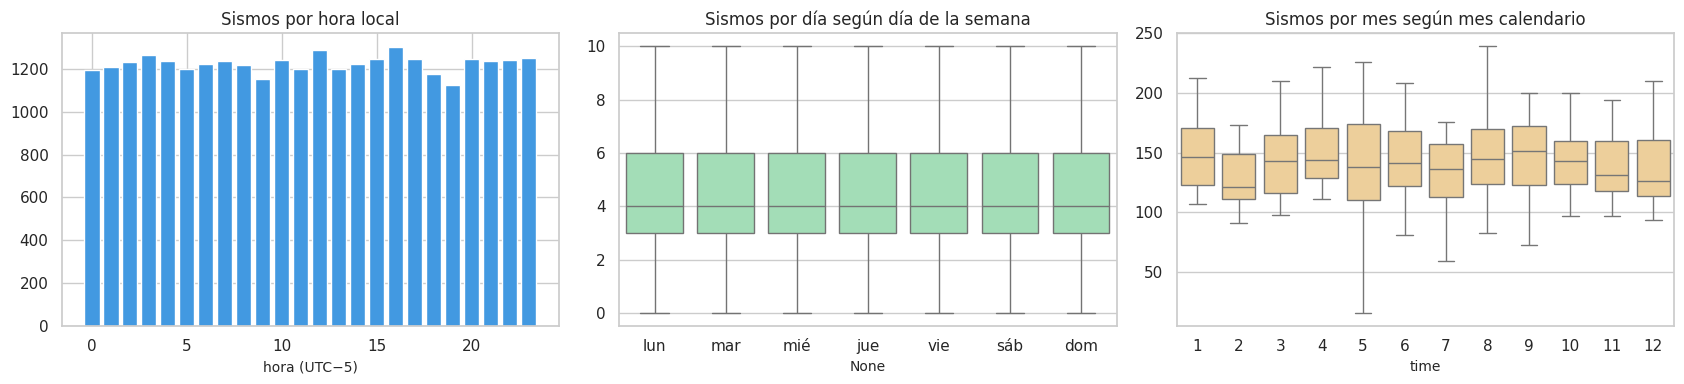

,ciclo,prueba,estadístico,p,efecto,p_Holm
0,hora local,χ² uniformidad,29.064771,0.178172,"razón noche (0–6 h) / esperado = 1,00",0.534516
1,día de la semana,Kruskal-Wallis (sismos diarios),2.680513,0.847744,"ε² = 0,0004",1.000000
2,mes calendario,Kruskal-Wallis (sismos mensuales),5.311084,0.915170,"ε² = 0,026",1.000000


In [6]:
# Patrones por hora local y día de la semana (posible sesgo de detección)
cat["hora_local"] = (cat.time - pd.Timedelta(hours=5)).dt.hour
cat["dia_semana"] = (cat.time - pd.Timedelta(hours=5)).dt.dayofweek
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
h = cat.hora_local.value_counts().sort_index()
axes[0].bar(h.index, h.values, color="#4299e1"); axes[0].set_title("Sismos por hora local"); axes[0].set_xlabel("hora (UTC−5)")
dsem = por_dia.groupby((por_dia.index - pd.Timedelta(hours=5)).dayofweek)
sns.boxplot(x=(por_dia.index - pd.Timedelta(hours=5)).dayofweek, y=por_dia.values, ax=axes[1], color="#9ae6b4", showfliers=False)
axes[1].set_xticks(range(7), ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]); axes[1].set_title("Sismos por día según día de la semana")
sns.boxplot(x=mensual.index.month, y=mensual.values, ax=axes[2], color="#fbd38d", showfliers=False); axes[2].set_title("Sismos por mes según mes calendario")
plt.tight_layout(); eda.guardar_figura(fig, "07_ciclos.png"); plt.show()
chi_h = stats.chisquare(h.values)
noche = cat.hora_local.isin(range(0, 6)).mean() / (6 / 24)
kw_dia = stats.kruskal(*[g.values for _, g in dsem])
kw_mes = stats.kruskal(*[mensual[mensual.index.month == m_].values for m_ in range(1, 13)])
ciclos = pd.DataFrame([
    ("hora local", "χ² uniformidad", chi_h.statistic, chi_h.pvalue, f"razón noche (0–6 h) / esperado = {es(noche, 2)}"),
    ("día de la semana", "Kruskal-Wallis (sismos diarios)", kw_dia.statistic, kw_dia.pvalue, f"ε² = {es(eda.epsilon_cuadrado(kw_dia.statistic, len(por_dia)), 4)}"),
    ("mes calendario", "Kruskal-Wallis (sismos mensuales)", kw_mes.statistic, kw_mes.pvalue, f"ε² = {es(eda.epsilon_cuadrado(kw_mes.statistic, len(mensual)), 3)}"),
], columns=["ciclo", "prueba", "estadístico", "p", "efecto"])
ciclos["p_Holm"] = eda.holm(ciclos.p)
eda.guardar_tabla(ciclos, "ciclos_temporales.csv")
ciclos

In [7]:
md(f"""**Interpretación.**
- **Serie mensual.** No tiene tendencia monótona. Muestra un nivel alto en 2004–2007, una caída en 2008 y una recuperación lenta
  desde 2017. Los picos aislados son enjambres.
- **Hora del día.** Los sismos M ≥ 2,5 se distribuyen de forma uniforme en las 24 horas (p de Holm = {p_fmt(ciclos.p_Holm[0])}; la madrugada
  local tiene {es(noche, 2)} veces lo esperado). Es una buena noticia de calidad: el ruido cultural nocturno y diurno (tráfico,
  industria) suele producir un ciclo diario de detección en los sismos pequeños, y su ausencia sugiere que a M ≥ 2,5 la detección
  no depende de la hora. En todo caso, el modelo agrega por mes.
- **Día de la semana.** p de Holm = {p_fmt(ciclos.p_Holm[1])}, efecto nulo: no hay patrón de fin de semana (por ejemplo, por menos analistas revisando).
- **Mes calendario.** Sin estacionalidad (p de Holm = {p_fmt(ciclos.p_Holm[2])}), lo que confirma los capítulos 3 y 5.""")

**Interpretación.**
- **Serie mensual.** No tiene tendencia monótona. Muestra un nivel alto en 2004–2007, una caída en 2008 y una recuperación lenta
  desde 2017. Los picos aislados son enjambres.
- **Hora del día.** Los sismos M ≥ 2,5 se distribuyen de forma uniforme en las 24 horas (p de Holm = 0,535; la madrugada
  local tiene 1,00 veces lo esperado). Es una buena noticia de calidad: el ruido cultural nocturno y diurno (tráfico,
  industria) suele producir un ciclo diario de detección en los sismos pequeños, y su ausencia sugiere que a M ≥ 2,5 la detección
  no depende de la hora. En todo caso, el modelo agrega por mes.
- **Día de la semana.** p de Holm = 1,000, efecto nulo: no hay patrón de fin de semana (por ejemplo, por menos analistas revisando).
- **Mes calendario.** Sin estacionalidad (p de Holm = 1,000), lo que confirma los capítulos 3 y 5.

## 7.3 Descomposición STL (tendencia, estacionalidad, residuo)

Se aplica STL robusta {cite}`cleveland1990stl` a log(1 + sismos por mes), con periodo 12.

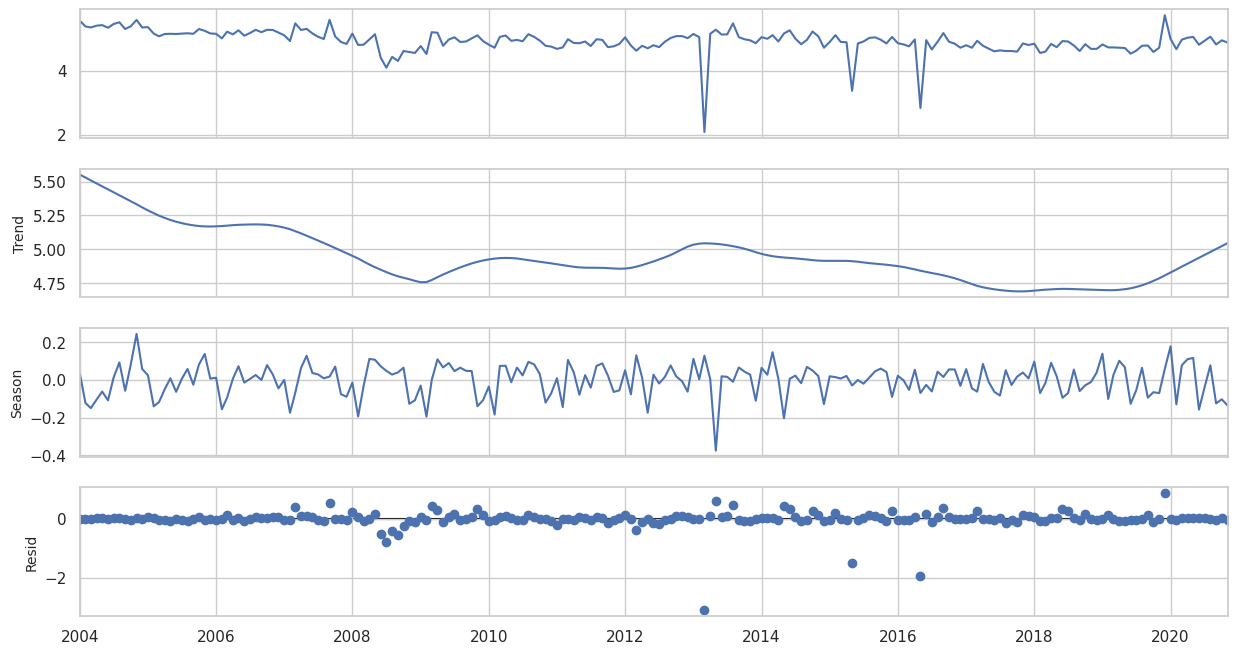

**Interpretación.** Con las medidas de Wang, Smith y Hyndman:
- **Fuerza de la tendencia = 0,26.** La tendencia (nivel de actividad de varios años) explica una parte modesta de la variación mensual;
  la mayor parte queda en el residuo.
- **Fuerza de la estacionalidad = 0,00.** Es prácticamente nula.
- **Residuo.** Concentra los enjambres (picos).
- **Implicaciones.**
  - El componente estacional ingenuo no aporta.
  - Lo que sí importa es el **nivel reciente**, de ahí las ventanas móviles de 1 a 12 meses.
  - Los picos del residuo indican que hay episodios no anticipables con la historia de la serie agregada.

In [8]:
# Descomposición STL (tendencia, estacionalidad, residuo) de log sismos/mes y fuerza de cada componente
serie = np.log1p(mensual)
stl = STL(serie, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(14, 7); eda.guardar_figura(fig, "07_stl.png"); plt.show()
var_r = np.var(stl.resid)
fuerza_tend = max(0, 1 - var_r / np.var(stl.trend + stl.resid))
fuerza_est = max(0, 1 - var_r / np.var(stl.seasonal + stl.resid))
md(f"""**Interpretación.** Con las medidas de Wang, Smith y Hyndman:
- **Fuerza de la tendencia = {es(fuerza_tend, 2)}.** La tendencia (nivel de actividad de varios años) explica una parte modesta de la variación mensual;
  la mayor parte queda en el residuo.
- **Fuerza de la estacionalidad = {es(fuerza_est, 2)}.** Es prácticamente nula.
- **Residuo.** Concentra los enjambres (picos).
- **Implicaciones.**
  - El componente estacional ingenuo no aporta.
  - Lo que sí importa es el **nivel reciente**, de ahí las ventanas móviles de 1 a 12 meses.
  - Los picos del residuo indican que hay episodios no anticipables con la historia de la serie agregada.""")

## 7.4 Estacionariedad: medias y varianzas móviles, ADF y KPSS

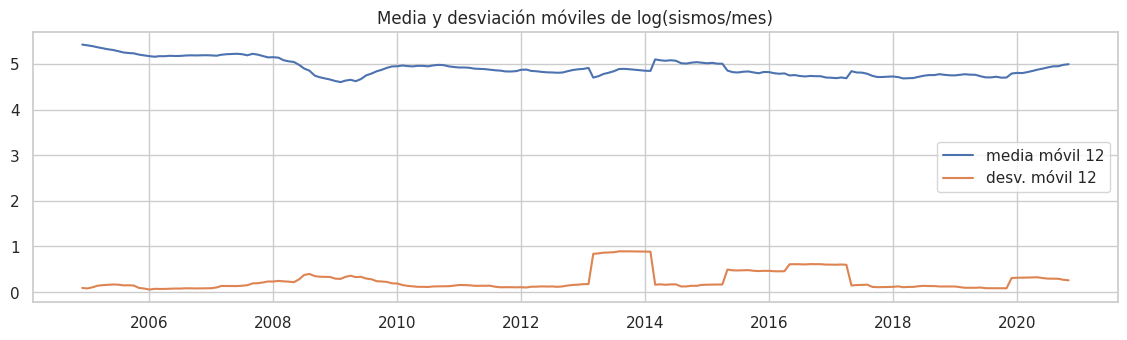

,serie,ADF_estad,ADF_p,KPSS_estad,KPSS_p
0,log sismos/mes (total),-10.7072,0.0,1.1540,0.01
1,diferencia de log sismos/mes,-7.5162,0.0,0.3214,0.10


In [9]:
# Estacionariedad: ADF y KPSS sobre la serie agregada y ADF por celda
filas = []
for nombre, s in (("log sismos/mes (total)", serie), ("diferencia de log sismos/mes", serie.diff().dropna())):
    adf = adfuller(s, autolag="AIC")
    kp = kpss(s, regression="c", nlags="auto")
    filas.append({"serie": nombre, "ADF_estad": adf[0], "ADF_p": adf[1], "KPSS_estad": kp[0], "KPSS_p": kp[1]})
# panel: ADF por celda sobre log(1+y) (celdas con suficiente variación)
adf_celda = []
for c_, g in P.groupby("celda"):
    s = g.sort_values("mes_obj").log_y.to_numpy()
    if s.std() > 0 and len(s) > 50:
        adf_celda.append(adfuller(s, autolag="AIC")[1])
est = pd.DataFrame(filas)
eda.guardar_tabla(est, "estacionariedad.csv")
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(serie.index, serie.rolling(12).mean(), label="media móvil 12"); ax.plot(serie.index, serie.rolling(12).std(), label="desv. móvil 12")
ax.legend(); ax.set_title("Media y desviación móviles de log(sismos/mes)"); eda.guardar_figura(fig, "07_moviles.png"); plt.show()
est.round(4)

In [10]:
md(f"""**Interpretación.**
- **Serie agregada.** Para log(sismos/mes), ADF {'rechaza' if est.ADF_p[0] < 0.05 else 'no rechaza'} la raíz unitaria (p = {es(est.ADF_p[0], 3)}) y KPSS
  {'rechaza' if est.KPSS_p[0] < 0.05 else 'no rechaza'} la estacionariedad (p = {es(est.KPSS_p[0], 3)}; statsmodels acota los p de KPSS entre 0,01 y 0,1).
  {'Las dos pruebas apuntan en direcciones opuestas: es el caso típico de una serie **estacionaria alrededor de un nivel que cambia lentamente** (cambios de régimen), no de un paseo aleatorio.' if (est.ADF_p[0] < 0.05 and est.KPSS_p[0] < 0.05) else ''}
  La media móvil confirma cambios de nivel y una varianza que no es constante.
- **Serie diferenciada.** Es estacionaria según ambas pruebas.
- **Por celda.** ADF rechaza la raíz unitaria en el {es(np.mean(np.array(adf_celda) < 0.05), 0, pct=True)} de las {len(adf_celda)} celdas con variación: las series
  individuales son mayoritariamente estacionarias en media.
- **Decisiones.**
  - Los modelos no usan el nivel absoluto del tiempo (no hay variable «año»), sino conteos de ventanas recientes, que se adaptan
    a los cambios de nivel.
  - La validación cruzada usa **ventanas crecientes** para que cada pliegue se evalúe en un periodo posterior a su entrenamiento.""")

**Interpretación.**
- **Serie agregada.** Para log(sismos/mes), ADF rechaza la raíz unitaria (p = 0,000) y KPSS
  rechaza la estacionariedad (p = 0,010; statsmodels acota los p de KPSS entre 0,01 y 0,1).
  Las dos pruebas apuntan en direcciones opuestas: es el caso típico de una serie **estacionaria alrededor de un nivel que cambia lentamente** (cambios de régimen), no de un paseo aleatorio.
  La media móvil confirma cambios de nivel y una varianza que no es constante.
- **Serie diferenciada.** Es estacionaria según ambas pruebas.
- **Por celda.** ADF rechaza la raíz unitaria en el 94 % de las 163 celdas con variación: las series
  individuales son mayoritariamente estacionarias en media.
- **Decisiones.**
  - Los modelos no usan el nivel absoluto del tiempo (no hay variable «año»), sino conteos de ventanas recientes, que se adaptan
    a los cambios de nivel.
  - La validación cruzada usa **ventanas crecientes** para que cada pliegue se evalúe en un periodo posterior a su entrenamiento.

## 7.5 Dependencia temporal: ACF, PACF y correlación cruzada con rezagos

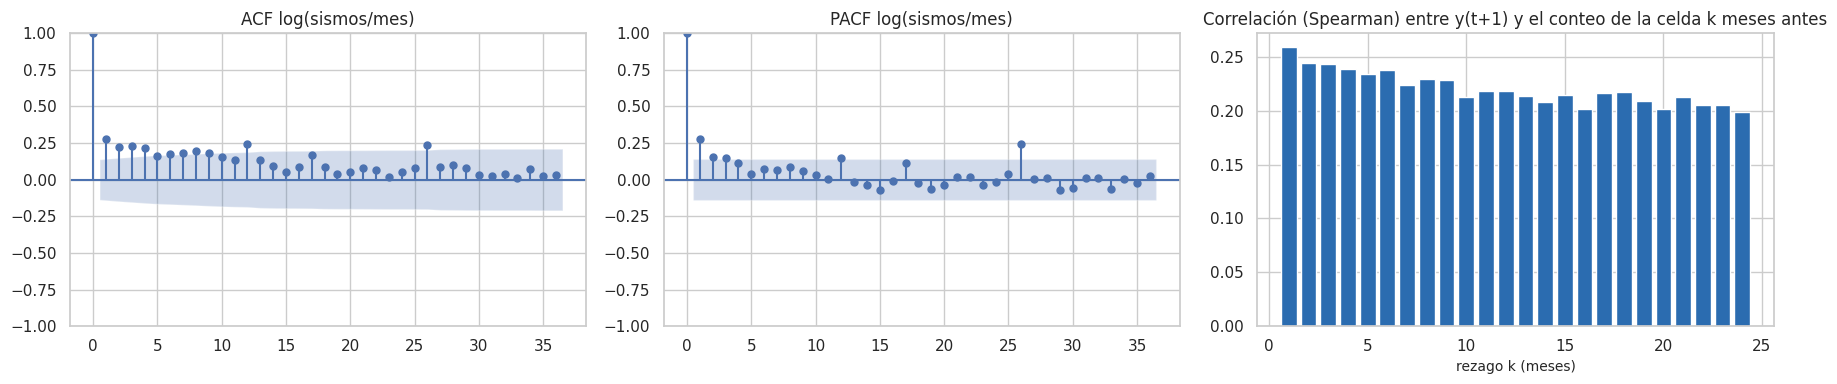

**Interpretación.**
- **Serie agregada.** La ACF decae **lentamente** (ρ(1) = 0,28, ρ(12) = 0,24) y la PACF corta tras los primeros rezagos. Es
  la firma de un proceso persistente, como un AR de orden bajo sobre un nivel que cambia lentamente.
- **Panel.** La correlación cruzada entre el conteo del mes siguiente y el conteo de la misma celda k meses antes es positiva
  en todos los rezagos y decae despacio: ρ = 0,26 con k = 1 y ρ = 0,22 con k = 12.
- **Implicaciones.**
  - Los rezagos útiles llegan a **un año**, lo que justifica las ventanas de 1, 3, 6 y 12 meses y el ingenuo estacional como
    variable, aunque su valor no venga de la estacionalidad sino de la persistencia.
  - La dependencia de corto plazo obliga a dejar un **gap** entre entrenamiento y validación/prueba.

In [11]:
# ACF y PACF de la serie y correlación cruzada en el panel por rezago
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(serie, lags=36, ax=axes[0]); axes[0].set_title("ACF log(sismos/mes)")
plot_pacf(serie, lags=36, ax=axes[1], method="ywm"); axes[1].set_title("PACF log(sismos/mes)")
# correlación cruzada en el panel: corr(log y_{c,t+1}, log n_c(t+1-k)) agregando todas las celdas
C = info["C"]
cc_ = info["cc"][tr]; tm_ = info["tm"][tr]
ccf = []
for k in range(1, 25):
    ok = tm_ - k >= 0
    a = np.log1p(info["y"][tr][ok]); b = np.log1p(C[cc_[ok], tm_[ok] - k])
    ccf.append(stats.spearmanr(a, b)[0])
axes[2].bar(range(1, 25), ccf, color="#2b6cb0"); axes[2].set_title("Correlación (Spearman) entre y(t+1) y el conteo de la celda k meses antes")
axes[2].set_xlabel("rezago k (meses)")
plt.tight_layout(); eda.guardar_figura(fig, "07_acf_pacf_ccf.png"); plt.show()
acf_v = acf(serie, nlags=24)
md(f"""**Interpretación.**
- **Serie agregada.** La ACF decae **lentamente** (ρ(1) = {es(acf_v[1], 2)}, ρ(12) = {es(acf_v[12], 2)}) y la PACF corta tras los primeros rezagos. Es
  la firma de un proceso persistente, como un AR de orden bajo sobre un nivel que cambia lentamente.
- **Panel.** La correlación cruzada entre el conteo del mes siguiente y el conteo de la misma celda k meses antes es positiva
  en todos los rezagos y decae despacio: ρ = {es(ccf[0], 2)} con k = 1 y ρ = {es(ccf[11], 2)} con k = 12.
- **Implicaciones.**
  - Los rezagos útiles llegan a **un año**, lo que justifica las ventanas de 1, 3, 6 y 12 meses y el ingenuo estacional como
    variable, aunque su valor no venga de la estacionalidad sino de la persistencia.
  - La dependencia de corto plazo obliga a dejar un **gap** entre entrenamiento y validación/prueba.""")

## 7.6 Cambios de régimen, puntos de cambio y efectos de calendario

Se buscan cambios en la **media** de log(sismos/mes) con segmentación binaria. En cada paso se divide
el segmento donde más se reduce la suma de cuadrados, y se acepta el corte si el BIC mejora (mínimo 12
meses por segmento).

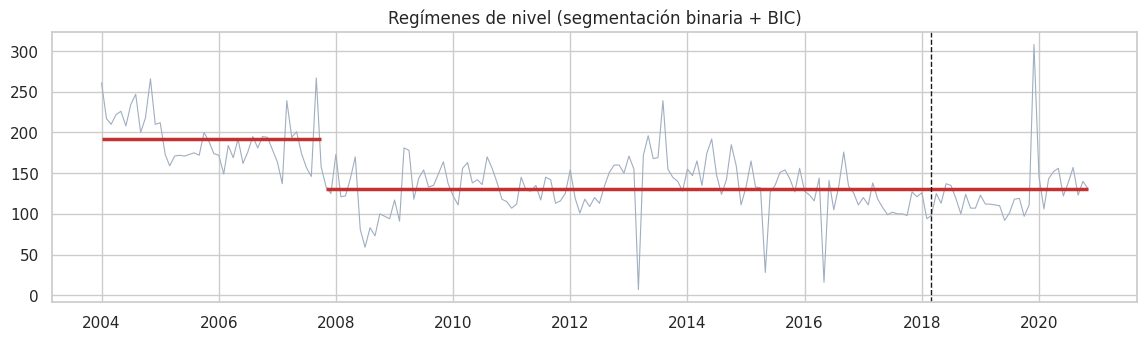

,desde,hasta,meses,media_sismos_mes
0,2004-01,2007-10,46,192.3
1,2007-11,2020-11,157,130.7


In [12]:
# Cambios de régimen: segmentación binaria de la media con criterio BIC
def segmentacion_binaria(x, min_seg=12, max_cortes=6):
    x = np.asarray(x, float); n = len(x)
    cortes = [0, n]
    def sse(a, b): return ((x[a:b] - x[a:b].mean()) ** 2).sum()
    def bic(cs): return n * np.log(sum(sse(a, b) for a, b in zip(cs[:-1], cs[1:])) / n) + (2 * (len(cs) - 1)) * np.log(n)
    while len(cortes) - 2 < max_cortes:
        mejor = None
        for a, b in zip(cortes[:-1], cortes[1:]):
            for k in range(a + min_seg, b - min_seg):
                ganancia = sse(a, b) - sse(a, k) - sse(k, b)
                if mejor is None or ganancia > mejor[0]:
                    mejor = (ganancia, k)
        if mejor is None:
            break
        nuevo = sorted(cortes + [mejor[1]])
        if bic(nuevo) >= bic(cortes):
            break
        cortes = nuevo
    return cortes

cortes = segmentacion_binaria(serie.values)
segs = pd.DataFrame([{"desde": serie.index[a].strftime("%Y-%m"), "hasta": serie.index[b - 1].strftime("%Y-%m"),
                      "meses": b - a, "media_sismos_mes": float(np.expm1(serie.values[a:b]).mean())}
                     for a, b in zip(cortes[:-1], cortes[1:])])
eda.guardar_tabla(segs, "regimenes.csv")
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(mensual.index, mensual.values, lw=0.8, color="#a0aec0")
for a, b in zip(cortes[:-1], cortes[1:]):
    ax.hlines(np.expm1(serie.values[a:b]).mean(), mensual.index[a], mensual.index[b - 1], colors="#c53030", lw=2.5)
ax.axvline(pd.Timestamp("2018-03-01"), ls="--", c="k", lw=1)
ax.set_title("Regímenes de nivel (segmentación binaria + BIC)"); eda.guardar_figura(fig, "07_regimenes.png"); plt.show()
segs.round(1)

In [13]:
md(f"""**Interpretación.**
- **Regímenes.** Se detectan **{len(segs)} regímenes** de nivel medio, entre {es(segs.media_sismos_mes.min(), 0)} y {es(segs.media_sismos_mes.max(), 0)} sismos/mes.
- **Cambio de portal (marzo de 2018).** {'Coincide con un punto de cambio, así que podría tener un efecto de detección o de escala de magnitud.' if any(s_.startswith('2018') for s_ in segs.desde) else 'No coincide con ningún punto de cambio: el paso entre portales no introduce un salto visible en la serie agregada.'}
  El único cambio detectado separa 2004–2007 (más activo) del resto del entrenamiento. Corresponde a una variación de la actividad
  (o de la detección) anterior a los dos portales.
- **Efectos de calendario.** No hay feriados ni temporadas que afecten a la Tierra. Los únicos efectos de calendario posibles serían de
  **detección** (hora del día, fines de semana o festivos con menos analistas), y la sección 7.2 mostró que no se observan.
- **Implicación.** Los cambios de régimen son la razón principal para usar ventanas móviles y para evaluar en un periodo de prueba
  posterior. También para medir la estabilidad del desempeño en varios cortes temporales (2018, 2021 y 2023 en el Entregable 2).""")

**Interpretación.**
- **Regímenes.** Se detectan **2 regímenes** de nivel medio, entre 131 y 192 sismos/mes.
- **Cambio de portal (marzo de 2018).** No coincide con ningún punto de cambio: el paso entre portales no introduce un salto visible en la serie agregada.
  El único cambio detectado separa 2004–2007 (más activo) del resto del entrenamiento. Corresponde a una variación de la actividad
  (o de la detección) anterior a los dos portales.
- **Efectos de calendario.** No hay feriados ni temporadas que afecten a la Tierra. Los únicos efectos de calendario posibles serían de
  **detección** (hora del día, fines de semana o festivos con menos analistas), y la sección 7.2 mostró que no se observan.
- **Implicación.** Los cambios de régimen son la razón principal para usar ventanas móviles y para evaluar en un periodo de prueba
  posterior. También para medir la estabilidad del desempeño en varios cortes temporales (2018, 2021 y 2023 en el Entregable 2).

## 7.7 Deriva temporal: *covariate shift* y *concept drift*

- **Dentro del entrenamiento.** Se compara la primera mitad (meses objetivo 2005–2012) con la segunda
  (2013–2020) usando el **PSI** (Population Stability Index) de cada predictora y del objetivo.
- **Entrenamiento contra prueba.** Se repite la comparación **solo de forma descriptiva**: no se usa
  para ninguna decisión.
- **Deriva de concepto.** Se compara la pendiente de log(1 + y) sobre log(1 + n_1m) entre periodos.

In [14]:
# Deriva: PSI de cada variable (2005–2012 frente a 2013–2020, y entrenamiento frente a prueba) y pendiente de la persistencia por periodo
fechas_tr = datos.fecha_de_mes(info["tm"][tr])
temprano = fechas_tr < "2013-01-01"
Xte = datos.panel_dataframe(X, info, te)
filas = []
for c in list(X.columns) + ["y"]:
    a = P.loc[temprano, c]; b = P.loc[~temprano, c]; t_ = Xte[c]
    filas.append({"variable": c, "PSI_2005-12_vs_2013-20": eda.psi(a, b), "PSI_entrenamiento_vs_prueba": eda.psi(P[c], t_)})
deriva = pd.DataFrame(filas).sort_values("PSI_2005-12_vs_2013-20", ascending=False)
eda.guardar_tabla(deriva, "deriva_psi.csv")
def pendiente(df):
    a = np.log1p(df.n_1m); b = df.log_y
    return float(np.polyfit(a, b, 1)[0])
concepto = pd.DataFrame([("2005–2012 (entrenamiento)", pendiente(P[temprano])), ("2013–2020 (entrenamiento)", pendiente(P[~temprano])),
                         ("2021–2026 (prueba, descriptivo)", pendiente(Xte))], columns=["periodo", "pendiente log y ~ log n_1m"])
eda.guardar_tabla(concepto, "deriva_concepto.csv")
display(deriva.round(3))
concepto.round(3)

,variable,PSI_2005-12_vs_2013-20,PSI_entrenamiento_vs_prueba
10,prof_media_hist,0.073,0.092
7,mag_media_12m,0.064,0.027
9,mag_max_12m,0.037,0.026
6,mag_media_3m,0.030,0.023
5,n35_12m,0.029,0.023
12,vec_3m,0.024,0.161
3,n_12m,0.022,0.153
11,vec_1m,0.020,0.049
8,mag_max_3m,0.016,0.006
2,n_6m,0.014,0.064


,periodo,pendiente log y ~ log n_1m
0,2005–2012 (entrenamiento),0.594
1,2013–2020 (entrenamiento),0.570
2,"2021–2026 (prueba, descriptivo)",0.660


In [15]:
md(f"""**Interpretación.**
- **Covariables dentro del entrenamiento.** La deriva es **débil**: ninguna variable supera PSI = 0,1. La mayor está en `{deriva.variable.iloc[0]}`
  (PSI = {es(deriva['PSI_2005-12_vs_2013-20'].iloc[0], 2)}), que es acumulativa por construcción, seguida de las magnitudes (mezcla de escalas,
  capítulo 2).
- **Objetivo.** PSI = {es(deriva.set_index('variable').loc['y', 'PSI_2005-12_vs_2013-20'], 3)}: su distribución marginal es estable.
- **Entrenamiento contra prueba.** Aparece una deriva **moderada** en {', '.join('`' + v + '`' for v in deriva.variable[deriva.PSI_entrenamiento_vs_prueba > 0.1])}
  (PSI > 0,1): en 2021–2026 hay más actividad acumulada a 12 meses y en la vecindad. Es coherente con el aumento de sismos de 2023–2026
  del capítulo 2.
- **Deriva de concepto.** La relación entre el conteo reciente y el del mes siguiente es estable dentro del entrenamiento (pendiente
  {es(concepto.iloc[0, 1], 2)} en 2005–2012 y {es(concepto.iloc[1, 1], 2)} en 2013–2020) y algo más fuerte en la prueba ({es(concepto.iloc[2, 1], 2)}): en el periodo
  reciente la actividad es más persistente.
- **Implicaciones.**
  - El riesgo de deriva es moderado y está en las variables de actividad acumulada.
  - Los modelos de árboles no extrapolan fuera del rango de entrenamiento, así que pueden subestimar meses más activos que los vistos.
    Los modelos lineales sí extrapolan.
  - Se evalúa la robustez del desempeño en varios cortes temporales (Entregable 2).""")

**Interpretación.**
- **Covariables dentro del entrenamiento.** La deriva es **débil**: ninguna variable supera PSI = 0,1. La mayor está en `prof_media_hist`
  (PSI = 0,07), que es acumulativa por construcción, seguida de las magnitudes (mezcla de escalas,
  capítulo 2).
- **Objetivo.** PSI = 0,005: su distribución marginal es estable.
- **Entrenamiento contra prueba.** Aparece una deriva **moderada** en `vec_3m`, `n_12m`
  (PSI > 0,1): en 2021–2026 hay más actividad acumulada a 12 meses y en la vecindad. Es coherente con el aumento de sismos de 2023–2026
  del capítulo 2.
- **Deriva de concepto.** La relación entre el conteo reciente y el del mes siguiente es estable dentro del entrenamiento (pendiente
  0,59 en 2005–2012 y 0,57 en 2013–2020) y algo más fuerte en la prueba (0,66): en el periodo
  reciente la actividad es más persistente.
- **Implicaciones.**
  - El riesgo de deriva es moderado y está en las variables de actividad acumulada.
  - Los modelos de árboles no extrapolan fuera del rango de entrenamiento, así que pueden subestimar meses más activos que los vistos.
    Los modelos lineales sí extrapolan.
  - Se evalúa la robustez del desempeño en varios cortes temporales (Entregable 2).

## 7.8 Panel: series por entidad (celda) y heterogeneidad

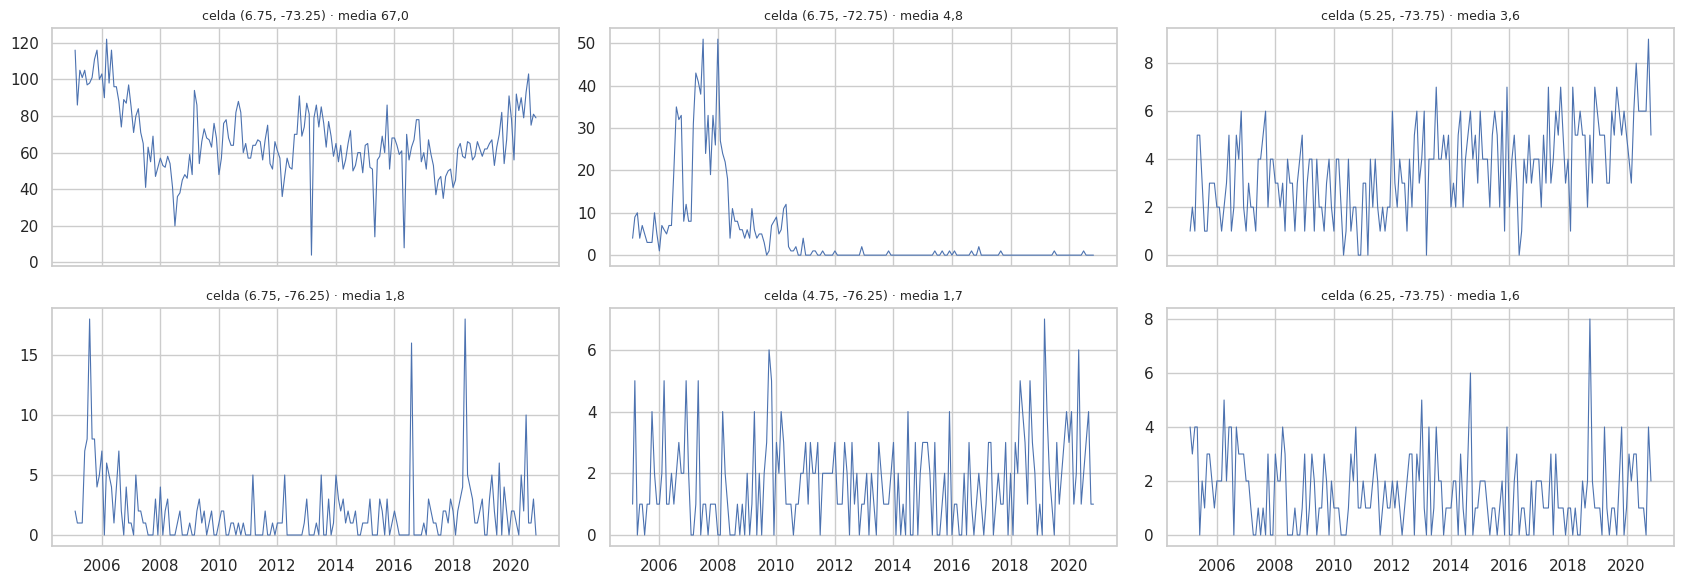

**Interpretación.**
- **Distintos tipos de dinámica.** Las seis celdas más activas muestran desde un **régimen persistente de alto nivel** (el nido, con decenas
  de sismos todos los meses) hasta **enjambres episódicos** (meses con cero y picos aislados).
- **Heterogeneidad entre celdas.**
  - El coeficiente de variación mensual va de 1,5 (p10) a 4,2 (p90).
  - La autocorrelación de orden 1 de log(1 + y) dentro de cada celda tiene mediana 0,06 y va de
    -0,05 a 0,29: la persistencia mes a mes es moderada en las celdas activas y casi nula en las
    tranquilas. Por eso las ventanas de varios meses (que promedian el ruido) informan más que el mes anterior solo.
- **Implicación.** Un modelo global necesita variables que distingan el régimen de cada celda (nivel histórico, profundidad,
  ubicación), como ya se concluyó en el capítulo 6.

In [16]:
# Series de las 6 celdas más activas
top = P.groupby("celda").y.sum().nlargest(6).index
fig, axes = plt.subplots(2, 3, figsize=(17, 6), sharex=True)
for ax, c_ in zip(axes.ravel(), top):
    g = P[P.celda == c_].sort_values("fecha_obj")
    ax.plot(g.fecha_obj, g.y, lw=0.8); ax.set_title(f"celda ({g.lat.iloc[0]}, {g.lon.iloc[0]}) · media {es(g.y.mean(), 1)}", fontsize=9)
plt.tight_layout(); eda.guardar_figura(fig, "07_series_por_celda.png"); plt.show()
het = P.groupby("celda").apply(lambda g: pd.Series({"media": g.y.mean(), "cv": g.y.std() / g.y.mean() if g.y.mean() > 0 else np.nan,
                                                     "acf1": g.sort_values("mes_obj").log_y.autocorr(1)}))
eda.guardar_tabla(het.reset_index(), "heterogeneidad_celdas.csv")
md(f"""**Interpretación.**
- **Distintos tipos de dinámica.** Las seis celdas más activas muestran desde un **régimen persistente de alto nivel** (el nido, con decenas
  de sismos todos los meses) hasta **enjambres episódicos** (meses con cero y picos aislados).
- **Heterogeneidad entre celdas.**
  - El coeficiente de variación mensual va de {es(het.cv.quantile(0.1), 1)} (p10) a {es(het.cv.quantile(0.9), 1)} (p90).
  - La autocorrelación de orden 1 de log(1 + y) dentro de cada celda tiene mediana {es(het.acf1.median(), 2)} y va de
    {es(het.acf1.quantile(0.1), 2)} a {es(het.acf1.quantile(0.9), 2)}: la persistencia mes a mes es moderada en las celdas activas y casi nula en las
    tranquilas. Por eso las ventanas de varios meses (que promedian el ruido) informan más que el mes anterior solo.
- **Implicación.** Un modelo global necesita variables que distingan el régimen de cada celda (nivel histórico, profundidad,
  ubicación), como ya se concluyó en el capítulo 6.""")

## 7.9 Consecuencias para el modelado

1. **Partición cronológica**, nunca aleatoria, con **gap de un mes** entre entrenamiento y prueba.
2. **Validación cruzada temporal de ventana creciente** con el mismo gap (5 pliegues sobre el último
   60 % de los meses de entrenamiento; `src/datos.py::pliegues_temporales`).
3. **Rezagos y ventanas solo con el pasado.** Las ventanas de 1, 3, 6 y 12 meses terminan en el mes *t*;
   el objetivo es *t* + 1.
4. **Sin variable de año ni tendencia determinista.** Los cambios de régimen no se extrapolan; el nivel
   reciente los recoge.
5. **Componentes cíclicos** (`sen_mes`, `cos_mes`) se incluyen por completitud, pero se espera que pesen
   poco: no hay estacionalidad.
6. **Riesgo de deriva** moderado en la actividad acumulada (prueba más activa). Se vigila con el
   desempeño por periodo y con varios cortes temporales.